
# Unemployment Analysis with Python

## 1. Importing Required Libraries



In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 2. Loading the Datasets


In [48]:
df1 = pd.read_csv("/content/Unemployment in India.csv")
df2 = pd.read_csv("/content/Unemployment_Rate_upto_11_2020.csv")
print("First Dataset:")
display(df1.head())
print("Second Dataset:")
display(df2.head())

First Dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Second Dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [49]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## 3. Data Inspection and Understanding


In [50]:
print("First dataset shape:", df1.shape)
print("Second dataset shape:", df2.shape)
print("\nFirst dataset columns:")
print(df1.columns.tolist())
print("\nSecond dataset columns:")
print(df2.columns.tolist())
print("\nFirst dataset information:")
df1.info()
print("\nSecond dataset information:")
df2.info()

First dataset shape: (768, 7)
Second dataset shape: (267, 9)

First dataset columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Second dataset columns:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

First dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimat


## 4. Data Cleaning and Preprocessing


In [51]:
# Remove extra spaces from column names
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()
# Remove completely blank rows
df1.dropna(how="all", inplace=True)
df2.dropna(how="all", inplace=True)
# Remove duplicate rows
df1.drop_duplicates(inplace=True)
df2.drop_duplicates(inplace=True)
# Convert Date column into datetime format
df1["Date"] = pd.to_datetime(
    df1["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)
df2["Date"] = pd.to_datetime(
    df2["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)
# Check missing values
print("Missing values in Dataset 1:")
print(df1.isnull().sum())
print("\nMissing values in Dataset 2:")
print(df2.isnull().sum())
print("\nDataset 1 shape after cleaning:", df1.shape)
print("Dataset 2 shape after cleaning:", df2.shape)

Missing values in Dataset 1:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

Missing values in Dataset 2:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64

Dataset 1 shape after cleaning: (740, 7)
Dataset 2 shape after cleaning: (267, 9)


In [52]:
unemployment_col = "Estimated Unemployment Rate (%)"
df1 = df1.dropna(
    subset=["Region", "Date", unemployment_col]
).copy()
df2 = df2.dropna(
    subset=["Region", "Date", unemployment_col]
).copy()
print("Dataset 1 after removing essential missing values:")
print(df1.shape)
print("\nDataset 2 after removing essential missing values:")
print(df2.shape)
print("\nFirst dataset sample:")
display(df1.head())

Dataset 1 after removing essential missing values:
(740, 7)

Dataset 2 after removing essential missing values:
(267, 9)

First dataset sample:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural



## 5. Exploratory Data Analysis (EDA)


In [53]:
print("DATASET 1 STATISTICS")
print("Average unemployment rate:",
      round(df1[unemployment_col].mean(), 2), "%")
print("Maximum unemployment rate:",
      round(df1[unemployment_col].max(), 2), "%")
print("Minimum unemployment rate:",
      round(df1[unemployment_col].min(), 2), "%")
print("\nDATASET 2 STATISTICS")
print("Average unemployment rate:",
      round(df2[unemployment_col].mean(), 2), "%")
print("Maximum unemployment rate:",
      round(df2[unemployment_col].max(), 2), "%")
print("Minimum unemployment rate:",
      round(df2[unemployment_col].min(), 2), "%")

DATASET 1 STATISTICS
Average unemployment rate: 11.79 %
Maximum unemployment rate: 76.74 %
Minimum unemployment rate: 0.0 %

DATASET 2 STATISTICS
Average unemployment rate: 12.24 %
Maximum unemployment rate: 75.85 %
Minimum unemployment rate: 0.5 %



## 6. Monthly Unemployment Trends in India


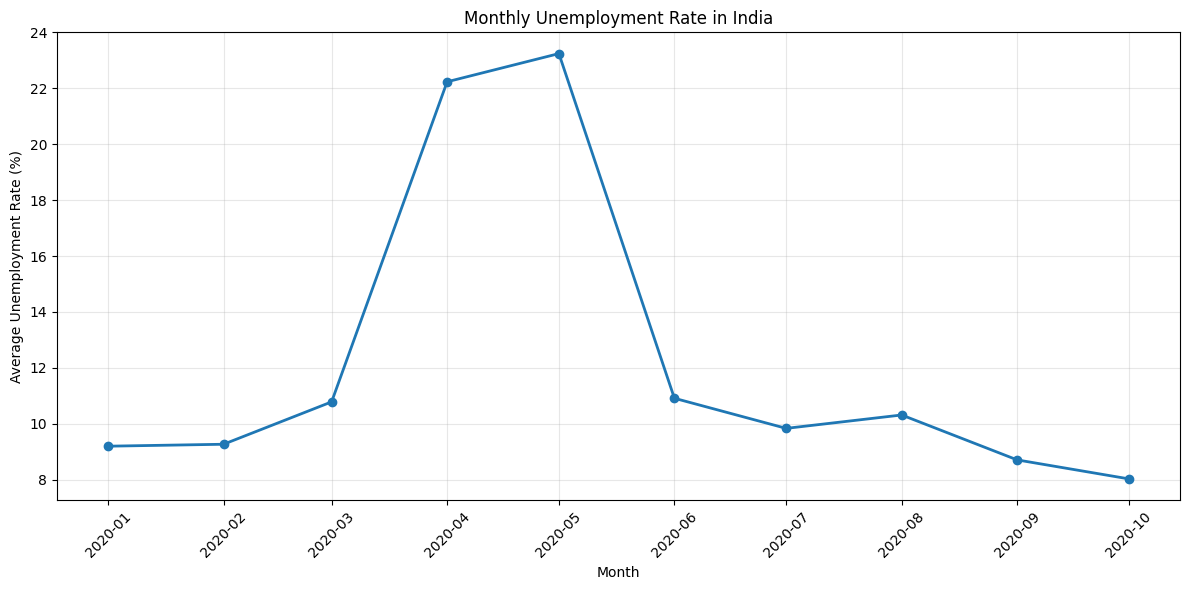

In [54]:
# Group records by month and calculate average unemployment
monthly_unemployment = (
    df2.groupby(df2["Date"].dt.to_period("M"))[unemployment_col]
       .mean()
)
monthly_unemployment.index = (
    monthly_unemployment.index.to_timestamp()
)
# Plot the trend
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)
plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Impact of COVID-19 on Unemployment in India


In [55]:
# Extract month from the date
df2["Month"] = df2["Date"].dt.month
# Categorize each month into a period
def period_label(month):
    if month in [1, 2]:
        return "Before lockdown"
    elif month == 3:
        return "March transition"
    elif month in [4, 5]:
        return "Initial lockdown"
    else:
        return "Later period"
df2["Period"] = df2["Month"].apply(period_label)
# Calculate average unemployment for each period
covid_summary = df2.groupby("Period")[
    "Estimated Unemployment Rate (%)"
].mean()
period_order = [
    "Before lockdown",
    "March transition",
    "Initial lockdown",
    "Later period"
]
covid_summary = covid_summary.reindex(period_order)
print("COVID-19 Impact Analysis")
print(covid_summary.round(2))
# Calculate the increase during initial lockdown
before = covid_summary["Before lockdown"]
during = covid_summary["Initial lockdown"]
print("\nIncrease during initial lockdown:",
      round(during - before, 2), "percentage points")
print("Percentage increase:",
      round(((during - before) / before) * 100, 2), "%")


COVID-19 Impact Analysis
Period
Before lockdown      9.23
March transition    10.78
Initial lockdown    22.75
Later period         9.56
Name: Estimated Unemployment Rate (%), dtype: float64

Increase during initial lockdown: 13.52 percentage points
Percentage increase: 146.44 %


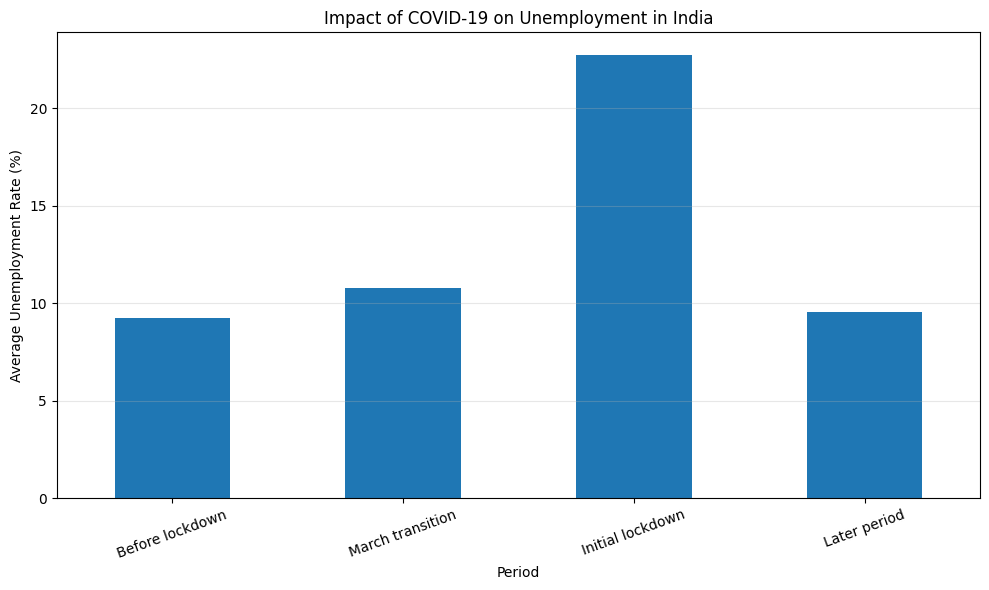

In [56]:
plt.figure(figsize=(10, 6))
covid_summary.plot(kind="bar")
plt.title("Impact of COVID-19 on Unemployment in India")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. State-Wise Unemployment Analysis


Top 10 Regions with Highest Average Unemployment Rate:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


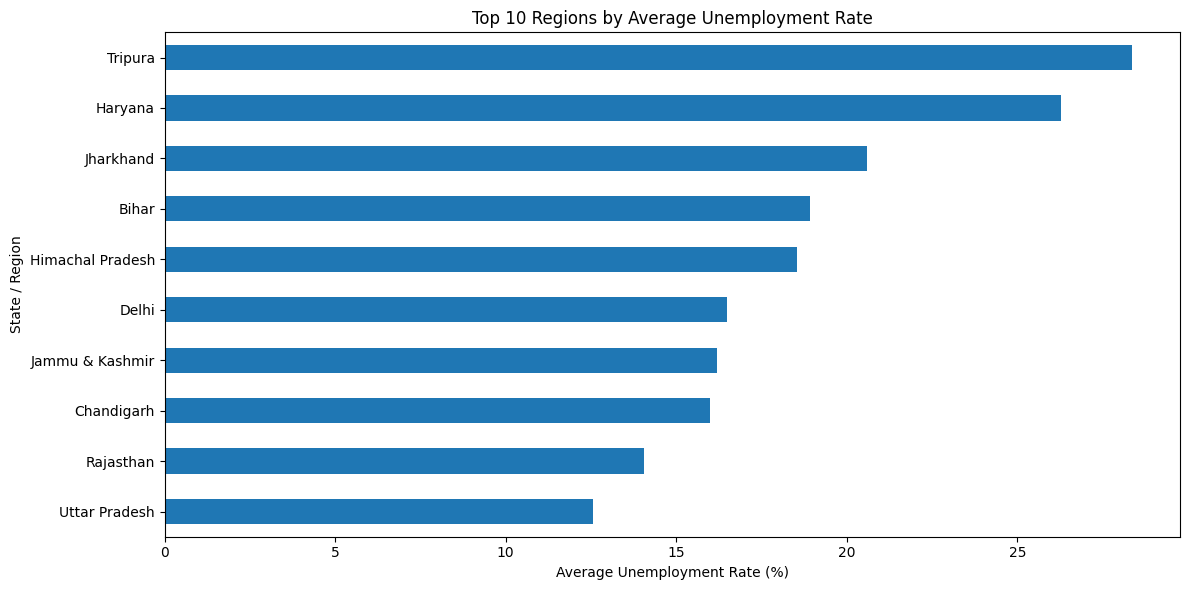

In [57]:
# Calculate average unemployment rate by region
state_unemployment = (
    df1.groupby("Region")["Estimated Unemployment Rate (%)"]
       .mean()
       .sort_values(ascending=False)
)
# Display the top 10 regions
print("Top 10 Regions with Highest Average Unemployment Rate:")
display(state_unemployment.head(10).round(2))
# Visualize the results
plt.figure(figsize=(12, 6))
state_unemployment.head(10).sort_values().plot(
    kind="barh"
)
plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("State / Region")
plt.tight_layout()
plt.show()


## 9. Rural vs Urban Unemployment Analysis


In [58]:
# Remove extra spaces from Area values
df1["Area"] = df1["Area"].astype(str).str.strip()
# Calculate average unemployment by area
area_unemployment = df1.groupby("Area")[
    "Estimated Unemployment Rate (%)"
].mean()
print("Average Unemployment Rate: Rural vs Urban")
print(area_unemployment.round(2))

Average Unemployment Rate: Rural vs Urban
Area
Rural    10.32
Urban    13.17
Name: Estimated Unemployment Rate (%), dtype: float64


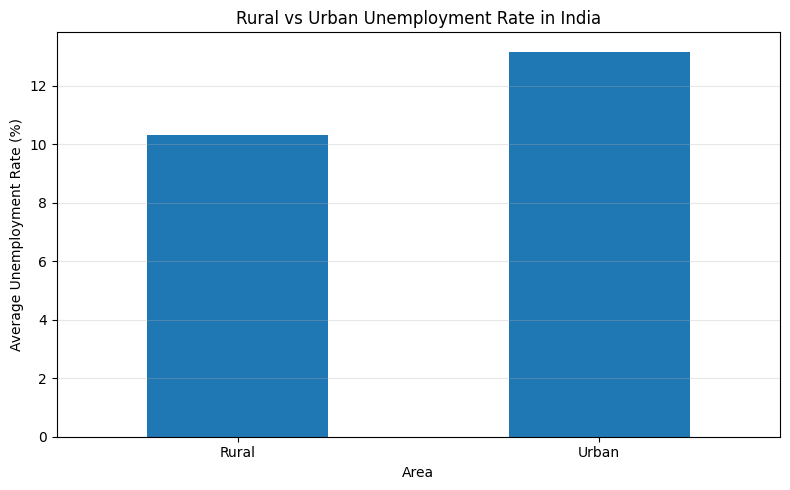

In [59]:
plt.figure(figsize=(8, 5))
area_unemployment.plot(
    kind="bar",
    width=0.5
)
plt.title("Rural vs Urban Unemployment Rate in India")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
if "Rural" in area_unemployment.index and "Urban" in area_unemployment.index:

    rural = area_unemployment["Rural"]
    urban = area_unemployment["Urban"]

    print("Rural Unemployment:", round(rural, 2), "%")
    print("Urban Unemployment:", round(urban, 2), "%")

    print("Difference:", round(abs(rural - urban), 2),
          "percentage points")

    if rural > urban:
        print("Rural areas have higher average unemployment.")
    else:
        print("Urban areas have higher average unemployment.")

else:
    print("Check the Area column values:", area_unemployment.index.tolist())


Rural Unemployment: 10.32 %
Urban Unemployment: 13.17 %
Difference: 2.84 percentage points
Urban areas have higher average unemployment.



## 10. Monthly and Seasonal Unemployment Patterns


In [61]:
# Extract month from Date
df1["Month"] = df1["Date"].dt.month
# Calculate average unemployment for each month
monthly_pattern = df1.groupby("Month")[
    "Estimated Unemployment Rate (%)"
].mean()
# Display results
month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}
monthly_pattern.index = monthly_pattern.index.map(month_names)
print("Average Unemployment Rate by Month:")
display(monthly_pattern.round(2))

Average Unemployment Rate by Month:


,Estimated Unemployment Rate (%)
Month,
January,9.95
February,9.96
March,10.70
April,23.64
May,16.65
June,10.55
July,9.03
August,9.64
September,9.05


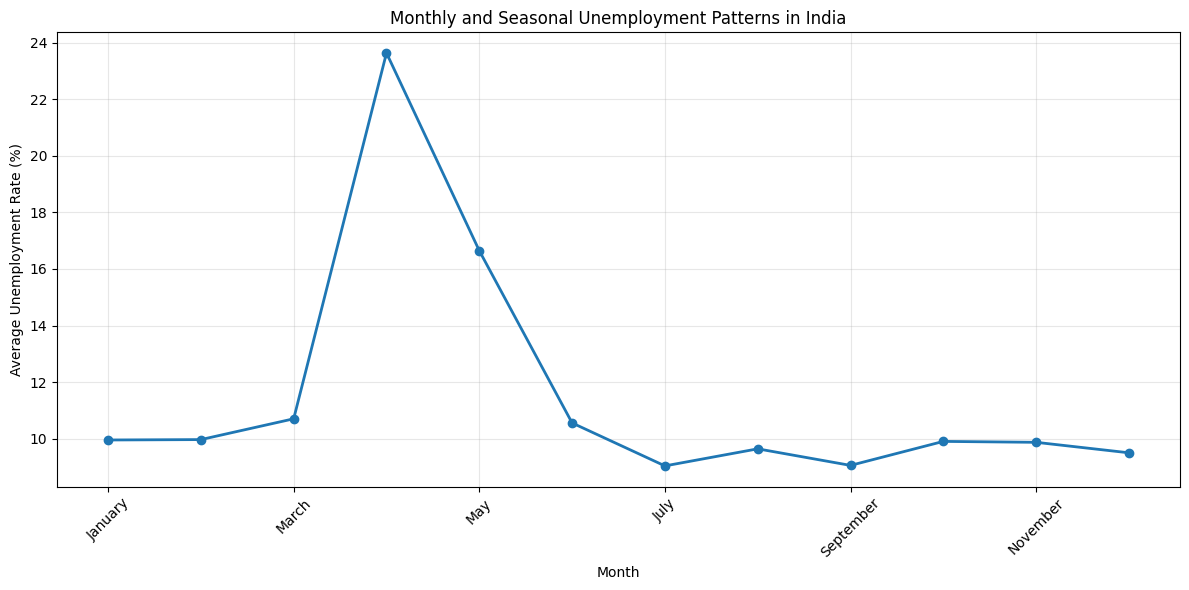

In [62]:
plt.figure(figsize=(12, 6))
monthly_pattern.plot(
    kind="line",
    marker="o",
    linewidth=2
)
plt.title("Monthly and Seasonal Unemployment Patterns in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
highest_month = monthly_pattern.idxmax()
lowest_month = monthly_pattern.idxmin()
print("Highest unemployment month:",
      highest_month,
      "-", round(monthly_pattern.max(), 2), "%")
print("Lowest unemployment month:",
      lowest_month,
      "-", round(monthly_pattern.min(), 2), "%")

Highest unemployment month: April - 23.64 %
Lowest unemployment month: July - 9.03 %



## 11. Correlation Analysis of Employment Indicators


In [64]:
# Select numerical columns
correlation_data = df1[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
]
# Calculate correlation
correlation_matrix = correlation_data.corr()
print("Correlation Matrix:")
display(correlation_matrix.round(2))

Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.00,-0.22,0.00
Estimated Employed,-0.22,1.00,0.01
Estimated Labour Participation Rate (%),0.00,0.01,1.00


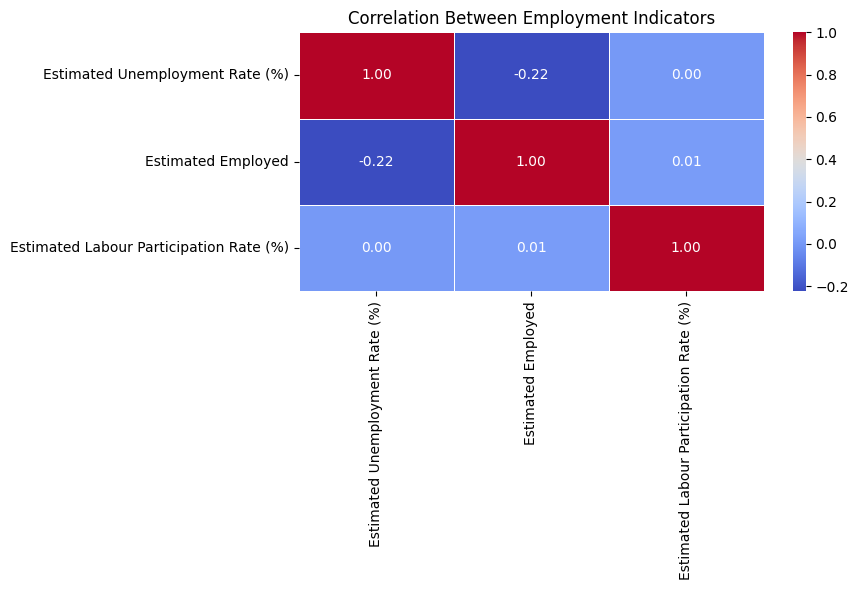

In [65]:
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()


## 12. Summary of Key Findings


In [66]:
print("=" * 55)
print("KEY FINDINGS - UNEMPLOYMENT ANALYSIS IN INDIA")
print("=" * 55)
print("\n1. OVERALL UNEMPLOYMENT")
print("Average unemployment rate:",
      round(df1["Estimated Unemployment Rate (%)"].mean(), 2), "%")
print("\n2. COVID-19 IMPACT")
print("Before lockdown:", round(before, 2), "%")
print("Initial lockdown:", round(during, 2), "%")
print("Increase:", round(during - before, 2), "percentage points")
print("\n3. STATE-WISE ANALYSIS")
print("Highest:", state_unemployment.index[0],
      "-", round(state_unemployment.iloc[0], 2), "%")
print("\n4. RURAL VS URBAN")
print(area_unemployment.round(2))
print("\n5. MONTHLY PATTERNS")
print("Highest month:", monthly_pattern.idxmax(),
      "-", round(monthly_pattern.max(), 2), "%")
print("Lowest month:", monthly_pattern.idxmin(),
      "-", round(monthly_pattern.min(), 2), "%")
print("\n6. CORRELATION")
print(correlation_matrix.round(2))
print("\n" + "=" * 55)
print("ANALYSIS COMPLETED")
print("=" * 55)

KEY FINDINGS - UNEMPLOYMENT ANALYSIS IN INDIA

1. OVERALL UNEMPLOYMENT
Average unemployment rate: 11.79 %

2. COVID-19 IMPACT
Before lockdown: 9.23 %
Initial lockdown: 22.75 %
Increase: 13.52 percentage points

3. STATE-WISE ANALYSIS
Highest: Tripura - 28.35 %

4. RURAL VS URBAN
Area
Rural    10.32
Urban    13.17
Name: Estimated Unemployment Rate (%), dtype: float64

5. MONTHLY PATTERNS
Highest month: April - 23.64 %
Lowest month: July - 9.03 %

6. CORRELATION
                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                     1.00   
Estimated Employed                                                 -0.22   
Estimated Labour Participation Rate (%)                             0.00   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                       -0.22   
Estimated Employed                                     1.00   
Estimated Labour Participation Rate (%)  


## Key Findings

1. The overall average unemployment rate in Dataset 1 was 11.79%.

2. During the initial COVID-19 lockdown, average unemployment increased from 9.23% to 22.75%.

3. Tripura recorded the highest average unemployment rate among the regions, at 28.35%.

4. Urban areas had a higher average unemployment rate (13.17%) than rural areas (10.32%).

5. April recorded the highest monthly average unemployment rate (23.64%), while July recorded the lowest (9.03%) in Dataset 1.

6. Correlation analysis showed a weak negative relationship between unemployment and estimated employment (-0.22).




## 13. Economic and Social Policy Recommendations


1. Skill Development:
Provide vocational training and digital skills programs to improve employability.

2. Rural Employment:
Encourage rural industries, agricultural businesses and self-employment opportunities.

3. Urban Job Creation:
Promote startups, small businesses and employment-intensive industries.

4. Crisis Management:
Develop employment support programs during economic emergencies.

5. Regional Development:
Focus on regions with relatively high unemployment and improve access to job opportunities.



## 14. Conclusion


This project analyzed unemployment trends in India using Python and two CSV datasets.

Data cleaning, exploratory data analysis and visualization helped identify important patterns in unemployment.

The analysis showed a sharp increase in unemployment during the initial COVID-19 lockdown period. It also highlighted regional differences, higher average unemployment in urban areas, and variations across different months.

Correlation analysis provided additional insights into the relationships between unemployment, estimated employment and labour force participation.

Overall, this project demonstrates how Python can be used for economic data analysis and visualization. The findings can help identify areas that may require employment support, skill development and targeted economic policies.
